# BRD4 WSH QM–MM progress figures — run record 2026-11-27

Companion to [BRD4_MD_Preparation_Workflow.ipynb](BRD4_MD_Preparation_Workflow.ipynb). Run IDs: WSH QM 7671783.sched01; WSH MM baseline 7672108.sched01. This snapshot contains the numerical observations shared in the CHPC conversation, not a completed torsion scan. Python cells are reproducible plotting code; they have not been executed on CHPC or in this GitHub notebook. Static preview figures below are generated directly from the same recorded arrays. Future runs should be appended with job ID, source log, date, input revision and status. Do not overwrite earlier observations.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("progress_figures_20261127")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.linewidth": 1.5, "lines.linewidth": 2, "savefig.dpi": 300, "figure.facecolor": "white", "axes.facecolor": "white"})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + ".png"), bbox_inches="tight")
    fig.savefig(OUT / (name + ".svg"), bbox_inches="tight")
    plt.show()


## 1. Maximum CGenFF penalties
Observed from RESI headers of the four CGenFF 5.0 streams. Penalties are analogy indicators, not measured errors.

In [ ]:
penalties = pd.DataFrame({"ligand":["NP01","NP02","NP09","WSH"],"parameter_penalty":[29,38,38,59],"charge_penalty":[13.754,8.947,8.967,21.132]})
penalties.to_csv(OUT / "penalties.csv", index=False)
fig, ax = plt.subplots(figsize=(7,5))
ax.bar(penalties.ligand, penalties.parameter_penalty, color=["#d97706"]*3+["#dc2626"])
ax.axhline(50, color="black", linestyle="--")
ax.set(ylabel="Maximum parameter penalty", xlabel="Ligand", ylim=(0,70))
ax.bar_label(ax.containers[0])
save(fig,"01_maximum_parameter_penalties")

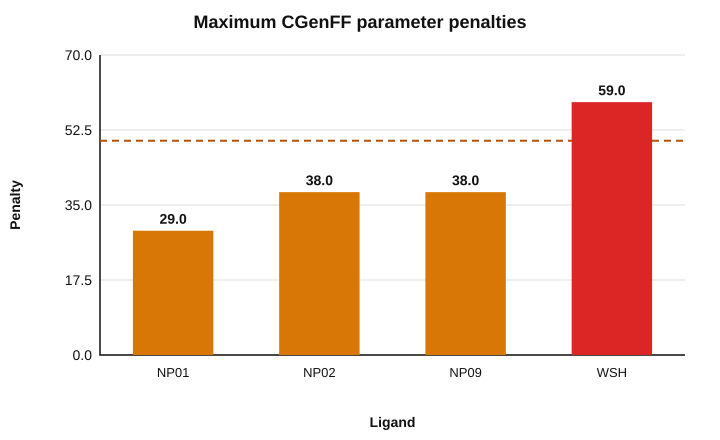

In [ ]:
# Recorded static preview; regenerate with plotting cell above.

## 2. WSH RI-MP2 Z-vector solver
Observed solver iterations 0–6 from the supplied ORCA log; iteration 7 had no completed residual in that excerpt. Threshold 1e-4. This is not geometry convergence.

In [ ]:
z = np.array([0.25694,0.090451,0.046871,0.020718,0.0097759,0.0040306,0.0018382])
pd.DataFrame({"iteration":np.arange(len(z)), "max_residual":z}).to_csv(OUT/"zvector.csv",index=False)
fig,ax=plt.subplots(figsize=(7,5))
ax.semilogy(np.arange(len(z)),z,"o-",color="#2563eb")
ax.axhline(1e-4,color="#b45309",ls="--",label="Solver tolerance")
ax.set(xlabel="Iteration",ylabel="Maximum residual",ylim=(1e-5,1))
ax.legend()
save(fig,"02_zvector_convergence")

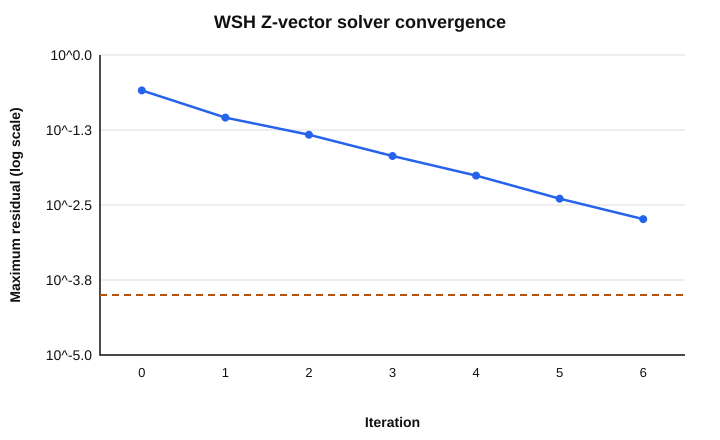

In [ ]:
# Recorded static preview; regenerate with plotting cell above.

## 3. Geometry optimisation energies — cycles 1–14
Source: WSH_OPT.out, job 7671783.sched01. Relative energies referenced to cycle 1. Conversion factor: 627.509474 kcal mol⁻¹ Eh⁻¹. All values are recorded outputs, not synthetic.

In [ ]:
energy = np.array([-1385.17673193914,-1385.195602571258,-1385.199476644872,-1385.200602050892,-1385.201069892174,-1385.201730510948,-1385.202269919863,-1385.202618375406,-1385.202783077013,-1385.202836613934,-1385.202871269521,-1385.20289826471,-1385.202910797305,-1385.202923002557])
cycle = np.arange(1,len(energy)+1)
relative = (energy-energy[0])*627.509474
pd.DataFrame({"cycle":cycle,"energy_Eh":energy,"relative_kcal_mol":relative}).to_csv(OUT/"geometry_energies.csv",index=False)
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(cycle,relative,"o-",color="#2563eb")
ax.set(xlabel="Geometry optimisation cycle",ylabel="Relative energy (kcal/mol)",xticks=cycle)
save(fig,"03_geometry_energy_profile")
print("Energy change from cycle 1:",relative[-1])

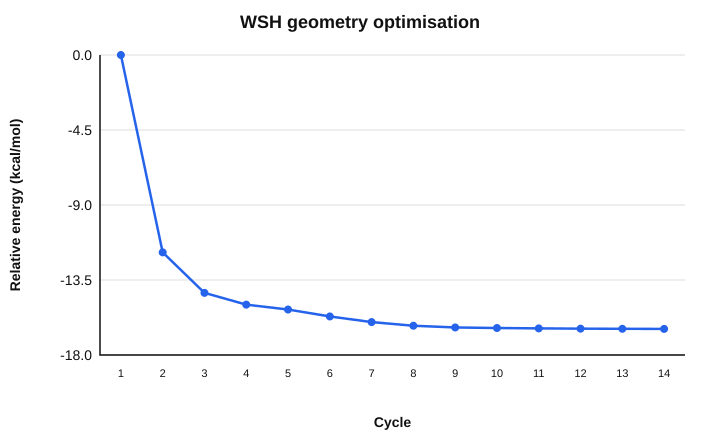

In [ ]:
# Recorded static preview; regenerate with plotting cell above.

## 4. Geometry convergence criteria — cycle 14
All five criteria were NO at this snapshot. Ratios are absolute values divided by the corresponding tolerance, avoiding mixing units. A ratio at or below 1 meets the individual threshold.

In [ ]:
qc = pd.DataFrame({"criterion":["Energy change","RMS gradient","MAX gradient","RMS step","MAX step"],"value":[-0.0000122053,0.000047005,0.0002441194,0.0036947899,0.0496427092],"tolerance":[0.000001,0.00003,0.0001,0.0006,0.001]})
qc["ratio"]=qc.value.abs()/qc.tolerance
qc.to_csv(OUT/"geometry_convergence.csv",index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.barh(qc.criterion,qc.ratio,color="#d97706")
ax.set_xscale("log")
ax.axvline(1,color="black",ls="--")
ax.set(xlabel="Absolute value / tolerance",xlim=(1,100))
ax.invert_yaxis()
save(fig,"04_geometry_convergence_criteria")

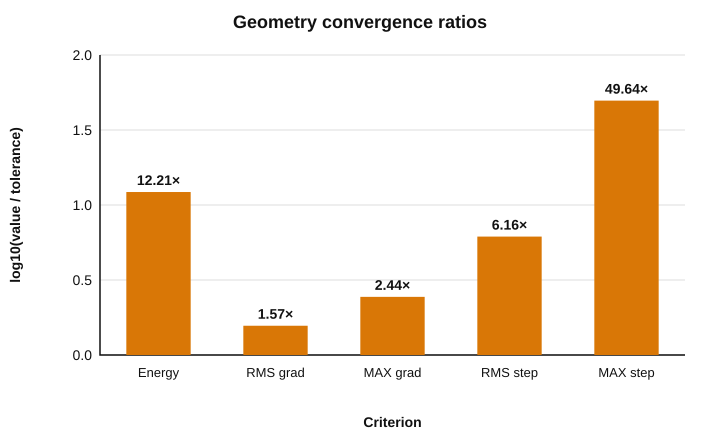

In [ ]:
# Recorded static preview; regenerate with plotting cell above.

## 5. MM baseline and future run records
WSH MM job 7672108.sched01: exit 0, walltime 1 s, baseline.edr 996 bytes. Energy menu available but numerical values were not yet supplied. No QM–MM energy profile exists yet. The earlier chat's schematic torsion and illustrative QM/MM/refined curves were conceptual examples only, not data and not used for reporting. Record the next real energy extraction, full QM scan, MM scan, parameter fitting (if required), and independent checks in separate dated run sections. Preserve original logs and topology files.

In [ ]:
# Run on CHPC separately, then transfer the XVG into this notebook's data folder:
# printf '1 2 3 4 5 6 7 8 9 0\n' | gmx_mpi energy -f baseline.edr -o baseline_energy.xvg
p=Path("baseline_energy.xvg")
if p.exists():
    rows=[line.split() for line in p.read_text().splitlines() if line.strip() and not line.lstrip().startswith(("#","@"))]
    cols=["time_ps","Bond","U-B","Proper-Dih.","Improper-Dih.","LJ-14","Coulomb-14","LJ-(SR)","Coulomb-(SR)","Potential"]
    if rows and all(len(row)==len(cols) for row in rows):
        df=pd.DataFrame(np.asarray(rows,dtype=float),columns=cols)
        df.to_csv(OUT/"baseline_mm_energy_kj_mol.csv",index=False)
        display(df)
    else:
        print("Unexpected or empty XVG; inspect header and selection.")
else:
    print("Pending: actual baseline_energy.xvg not provided.")